# Comparative Analysis of Learning Paradigms for Text Classification

This notebook solves a six-class emotion classification task using the `dair-ai/emotion` dataset. The dataset contains short English text messages, and each message is labeled as one of six emotions: sadness, joy, love, anger, fear, or surprise.

The goal of this project is not only to train one model, but to compare three different learning paradigms on the same task:

1. **From-scratch learning using an RNN/LSTM**: the model learns word embeddings and sequence patterns only from the labeled training data.
2. **Transfer learning using DistilBERT**: a pretrained transformer model is fine-tuned on the emotion classification dataset.
3. **LLM prompting using FLAN-T5**: an instruction-tuned language model classifies emotions without gradient updates, using zero-shot, few-shot, and chain-of-thought prompts.

The notebook also includes a data efficiency experiment to compare how the RNN and transformer behave when only a small balanced subset of 500 training examples is available. Finally, the models are compared using accuracy, macro F1 score, confusion matrices, training time, inference time, and practical suitability for real-world use.

Overall, this notebook demonstrates what pretraining adds to NLP: better language understanding, stronger performance with limited labeled data, and different trade-offs between training cost, inference cost, interpretability, and deployment practicality.


## Cell 1 — Install and Import the Main Libraries

This cell prepares the notebook environment by importing the main libraries used throughout the project. PyTorch is used to build and train the from-scratch LSTM model. Hugging Face `datasets` loads the emotion dataset, while Hugging Face `transformers` provides the pretrained DistilBERT model and tokenizer. NumPy, pandas, scikit-learn, matplotlib, and seaborn are used for numerical work, metrics, tables, and visualizations. The `time` module is imported because the assignment requires measuring both training time and inference time.

The installation commands make sure the required external libraries are available in the runtime before the rest of the notebook is executed.


In [6]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from collections import Counter
import time

# Install required libraries
!pip install datasets transformers torch scikit-learn matplotlib seaborn bitsandbytes accelerate evaluate


## Cell 2 — Re-import Libraries After Installation

This cell repeats the imports after installing the required packages. In notebook environments such as Google Colab, installing packages and importing them can sometimes be separated to avoid runtime issues. Re-importing here makes the notebook more stable after a fresh restart because all required modules are loaded before the dataset and models are created.

Although this repeats some imports from the previous cell, it does not affect the results. It only ensures that the environment is ready for the following cells.


In [7]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from collections import Counter
import time

## Cell 3 — Load the Emotion Dataset

This cell loads the `dair-ai/emotion` dataset from the Hugging Face Hub. The dataset is already split into training, validation, and test sets, so no manual split is required. Printing the dataset structure confirms that the expected splits are available, and printing one training example helps verify the format of the data.

Each example contains two main fields: the text itself and its numeric emotion label. The numeric label will later be mapped to the corresponding emotion name.


In [8]:
# Load the emotion dataset
dataset = load_dataset("dair-ai/emotion")

# Inspect the structure
print(dataset)
print("\nSample from training set:")
print(dataset['train'][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Sample from training set:
{'text': 'i didnt feel humiliated', 'label': 0}


## Cell 4 — Inspect Splits and Class Distribution

This cell reports the number of examples in each split and checks how the emotion labels are distributed in the training set. This is an important exploratory step because imbalanced classes can make accuracy misleading. For example, a model may achieve good accuracy by focusing on frequent classes while performing poorly on rare emotions.

The label names are extracted from the dataset metadata so that later results can be displayed using readable labels such as `joy`, `sadness`, and `anger` instead of only numeric class IDs.


In [9]:
# Number of examples per split
print("Dataset splits:")
for split in ['train', 'validation', 'test']:
    print(f"{split}: {len(dataset[split])} examples")

# Class distribution
label_names = dataset["train"].features["label"].names
train_labels = dataset['train']['label']
print("\nClass distribution in training set:")
label_counts = Counter(train_labels)
for label_id, count in sorted(label_counts.items()):
    print(f"{label_names[label_id]}: {count} ({count/len(train_labels)*100:.1f}%)")

Dataset splits:
train: 16000 examples
validation: 2000 examples
test: 2000 examples

Class distribution in training set:
sadness: 4666 (29.2%)
joy: 5362 (33.5%)
love: 1304 (8.2%)
anger: 2159 (13.5%)
fear: 1937 (12.1%)
surprise: 572 (3.6%)


## Cell 5 — Analyze Text Lengths

This cell calculates the number of words in each training text and prints basic statistics such as the mean, median, minimum, and maximum length. This helps justify the maximum sequence length used later during tokenization.

Since the texts are short, the RNN does not need a very large input length. Choosing a reasonable maximum length reduces unnecessary padding and makes training faster while still preserving most of the useful information in the text.


In [10]:
# Analyze text lengths
train_texts = dataset['train']['text']
text_lengths = [len(text.split()) for text in train_texts]

print(f"Text length statistics (in words):")
print(f"Mean: {np.mean(text_lengths):.1f}")
print(f"Median: {np.median(text_lengths):.1f}")
print(f"Max: {np.max(text_lengths)}")
print(f"Min: {np.min(text_lengths)}")

Text length statistics (in words):
Mean: 19.2
Median: 17.0
Max: 66
Min: 2


## Cell 6 — Visualize Class Balance and Text Length Distribution

This cell creates two exploratory visualizations. The first plot shows the number of training examples per emotion class, which makes class imbalance easier to see visually. The second plot shows the distribution of text lengths.

These plots support the preprocessing decisions made later in the notebook. The class distribution helps explain why macro F1 is important, while the length histogram helps justify fixed-length padding and truncation.


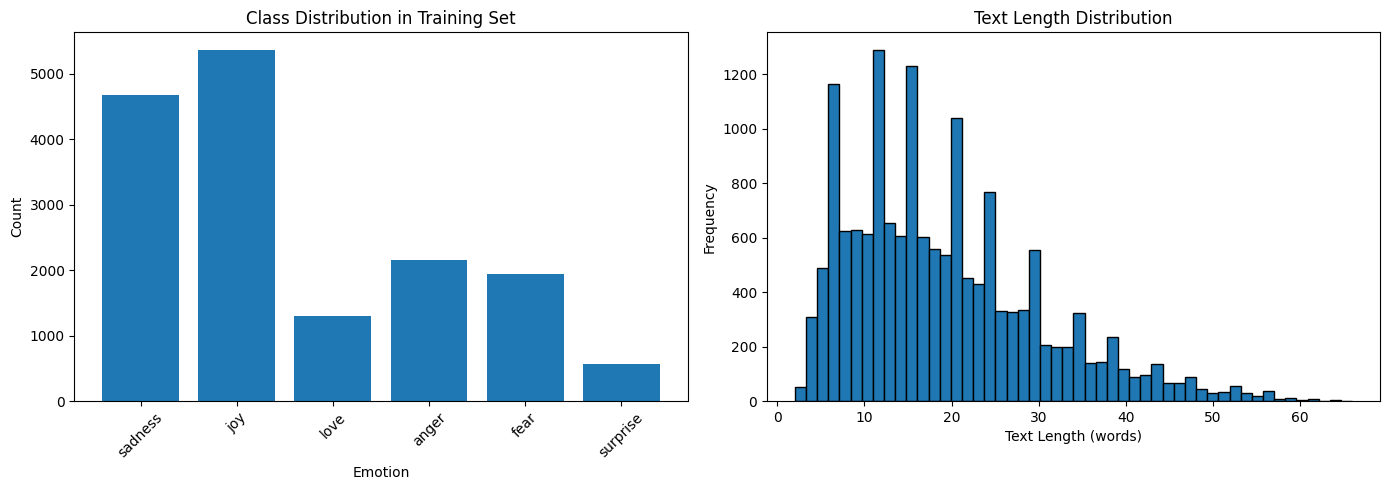

In [11]:
# Class distribution bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Class balance
ax1.bar(label_names, [label_counts[i] for i in range(6)])
ax1.set_xlabel('Emotion')
ax1.set_ylabel('Count')
ax1.set_title('Class Distribution in Training Set')
ax1.tick_params(axis='x', rotation=45)

# Text length histogram
ax2.hist(text_lengths, bins=50, edgecolor='black')
ax2.set_xlabel('Text Length (words)')
ax2.set_ylabel('Frequency')
ax2.set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

## Cell 7 — Build a Custom Vocabulary for the RNN

This cell builds a vocabulary specifically for the from-scratch RNN model. The RNN cannot directly understand raw words, so each word must be converted into a numeric ID. The vocabulary is created only from the training texts to avoid leaking information from the validation or test sets.

Two special tokens are added. `<PAD>` is used to fill shorter sequences up to the same length, and `<UNK>` is used for words that were not seen often enough in the training data. The minimum frequency threshold removes very rare words, which reduces vocabulary size and noise.


In [12]:
# Build vocabulary from training data
from collections import defaultdict

def build_vocab(texts, min_freq=2):
    """Build vocabulary from texts"""
    word_counts = defaultdict(int)
    for text in texts:
        for word in text.lower().split():
            word_counts[word] += 1

    # Keep words that appear at least min_freq times
    vocab = {'<PAD>': 0, '<UNK>': 1}
    idx = 2
    for word, count in word_counts.items():
        if count >= min_freq:
            vocab[word] = idx
            idx += 1

    return vocab

vocab = build_vocab(dataset['train']['text'])
print(f"Vocabulary size: {len(vocab)}")

Vocabulary size: 7401


## Cell 8 — Define the RNN Tokenization Function

This cell defines the custom tokenizer used by the LSTM model. The text is lowercased, split into words, converted into vocabulary IDs, and then padded or truncated to a fixed maximum length.

This tokenizer is simple compared to transformer tokenizers, but it is appropriate for the from-scratch baseline because the model is expected to learn embeddings from the dataset itself. The printed example verifies that the text-to-number conversion works correctly.


In [13]:
def tokenize_text(text, vocab, max_length=50):
    """Convert text to sequence of integers"""
    tokens = text.lower().split()
    indices = [vocab.get(token, vocab['<UNK>']) for token in tokens]

    # Pad or truncate
    if len(indices) < max_length:
        indices += [vocab['<PAD>']] * (max_length - len(indices))
    else:
        indices = indices[:max_length]

    return indices

# Test it
sample_text = dataset['train'][0]['text']
print(f"Original: {sample_text}")
print(f"Tokenized: {tokenize_text(sample_text, vocab)[:20]}...")  # Show first 20

Original: i didnt feel humiliated
Tokenized: [2, 3, 4, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...


## Cell 9 — Load the Pretrained DistilBERT Tokenizer

This cell loads the `distilbert-base-uncased` tokenizer. Unlike the custom RNN tokenizer, this tokenizer uses a pretrained subword vocabulary. This means it can handle many words and word fragments even if they did not appear in the emotion dataset.

The tokenizer creates input IDs and attention masks, which are required by DistilBERT. The sample output confirms that tokenization works and that the sequence is padded or truncated to the selected maximum length.


In [14]:
# For BERT and LLM
bert_tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

# Test it
encoded = bert_tokenizer(sample_text, truncation=True, padding='max_length', max_length=128)
print(f"\nBERT tokenization of same text:")
print(f"Input IDs length: {len(encoded['input_ids'])}")
print(f"First 20 tokens: {encoded['input_ids'][:20]}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


BERT tokenization of same text:
Input IDs length: 128
First 20 tokens: [101, 1045, 2134, 2102, 2514, 26608, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Cell 10 — Convert the Dataset into RNN Tensors

This cell applies the custom RNN tokenizer to the training, validation, and test splits. The resulting token IDs and labels are converted into PyTorch tensors so they can be used by the LSTM model.

The maximum sequence length is set to 50 based on the earlier text length analysis. This means each example will have exactly 50 token positions, either by truncating longer texts or padding shorter texts.


In [15]:
# Tokenize all splits
MAX_LENGTH = 50  # Based on your text length analysis

def prepare_data(dataset_split, vocab, max_length):
    texts = [tokenize_text(text, vocab, max_length) for text in dataset_split['text']]
    labels = dataset_split['label']
    return torch.LongTensor(texts), torch.LongTensor(labels)

train_X, train_y = prepare_data(dataset['train'], vocab, MAX_LENGTH)
val_X, val_y = prepare_data(dataset['validation'], vocab, MAX_LENGTH)
test_X, test_y = prepare_data(dataset['test'], vocab, MAX_LENGTH)

print(f"Training data shape: {train_X.shape}")
print(f"Training labels shape: {train_y.shape}")

Training data shape: torch.Size([16000, 50])
Training labels shape: torch.Size([16000])


## Cell 11 — Create PyTorch Datasets and DataLoaders

This cell wraps the tensor data into `TensorDataset` objects and then creates `DataLoader` objects. DataLoaders are important because they divide the data into mini-batches during training and evaluation.

The training DataLoader uses shuffling so that the model does not see the examples in the same order every epoch. The validation and test DataLoaders do not need shuffling because they are only used for evaluation.


In [16]:
# Create PyTorch datasets and loaders
BATCH_SIZE = 32

train_dataset = TensorDataset(train_X, train_y)
val_dataset = TensorDataset(val_X, val_y)
test_dataset = TensorDataset(test_X, test_y)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

## Cell 12 — Define the LSTM Classifier Architecture

This cell defines the from-scratch recurrent neural network model. The model starts with an embedding layer that converts word IDs into dense vectors. These embeddings are learned from the emotion dataset itself, unlike DistilBERT embeddings which are pretrained.

The LSTM layer then processes the sequence of word embeddings and captures information from the text order. Finally, a dense classification layer maps the learned sequence representation to the six emotion classes. This model is the baseline because it learns everything only from the labeled training data.


In [17]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, num_layers=2):
        super(LSTMClassifier, self).__init__()

        # Embedding layer - converts word indices to dense vectors
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        # LSTM layer - learns sequential patterns
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers,
                           batch_first=True, dropout=0.3, bidirectional=True)

        # Classification head - maps LSTM output to 6 classes
        # *2 because bidirectional
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        # x shape: (batch_size, seq_length)
        embedded = self.embedding(x)  # (batch_size, seq_length, embedding_dim)

        lstm_out, (hidden, cell) = self.lstm(embedded)

        # Use the last hidden state from both directions
        # Concatenate forward and backward final hidden states
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)

        output = self.dropout(hidden)
        output = self.fc(output)

        return output

# Initialize model
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
NUM_CLASSES = 6

model_rnn = LSTMClassifier(len(vocab), EMBEDDING_DIM, HIDDEN_DIM, NUM_CLASSES)
print(f"Model has {sum(p.numel() for p in model_rnn.parameters())} parameters")

Model has 1372426 parameters


## Cell 13 — Define Training and Validation Functions for the RNN

This cell defines reusable functions for one training epoch and one validation pass. During training, the model performs a forward pass, calculates the loss, backpropagates the gradients, and updates the weights using the optimizer.

During validation, the model is evaluated without updating the weights. This separation is important because validation performance is used to monitor whether the model is learning well or overfitting.


In [18]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch_X, batch_y in loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == batch_y).sum().item()
        total += batch_y.size(0)

    return total_loss / len(loader), correct / total

def evaluate_rnn(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == batch_y).sum().item()
            total += batch_y.size(0)

    return total_loss / len(loader), correct / total

## Cell 14 — Train the LSTM Model and Measure Training Time

This cell trains the from-scratch LSTM model. It selects GPU if available, defines the loss function, chooses the Adam optimizer, and runs training for the selected number of epochs.

The cell stores training and validation loss and accuracy after each epoch. It also measures the total training time, which is required for comparing the cost of the RNN against the transformer and LLM approaches.


In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_rnn = model_rnn.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_rnn.parameters(), lr=0.001)

EPOCHS = 5

train_losses, val_losses = [], []
train_accs, val_accs = [], []

rnn_train_start = time.time()

for epoch in range(EPOCHS):
    start = time.time()

    train_loss, train_acc = train_epoch(model_rnn, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate_rnn(model_rnn, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Time: {time.time() - start:.2f}s\n")

rnn_train_time = time.time() - rnn_train_start

print(f"Total RNN Training Time: {rnn_train_time:.2f} seconds")


Epoch 1
Train Loss: 1.3899 | Train Acc: 0.4579
Val Loss: 0.9554 | Val Acc: 0.6790
Time: 12.00s

Epoch 2
Train Loss: 0.7072 | Train Acc: 0.7631
Val Loss: 0.5253 | Val Acc: 0.8160
Time: 6.51s

Epoch 3
Train Loss: 0.3616 | Train Acc: 0.8772
Val Loss: 0.3362 | Val Acc: 0.8865
Time: 8.26s

Epoch 4
Train Loss: 0.2233 | Train Acc: 0.9225
Val Loss: 0.2930 | Val Acc: 0.8890
Time: 3.59s

Epoch 5
Train Loss: 0.1532 | Train Acc: 0.9453
Val Loss: 0.2611 | Val Acc: 0.9085
Time: 4.06s

Total RNN Training Time: 34.41 seconds


## Cell 15 — Plot RNN Training and Validation Curves

This cell plots the RNN's training and validation loss and accuracy across epochs. These curves show whether the model is learning properly.

If training loss decreases but validation performance does not improve, this may indicate overfitting. If both training and validation performance improve, the model is learning useful patterns from the dataset.


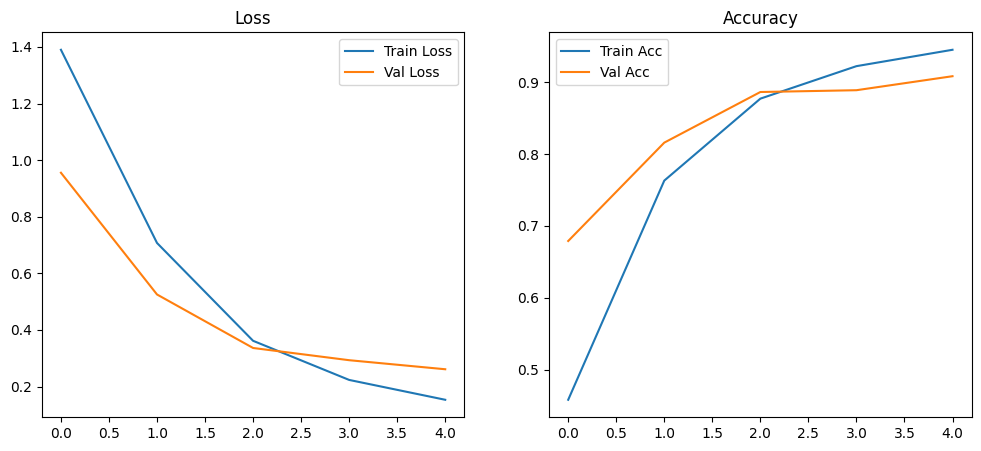

In [20]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")

plt.subplot(1,2,2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")

plt.show()

## Cell 16 — Run RNN Inference on the Test Set

This cell evaluates the trained RNN on the test set. The model is switched to evaluation mode and gradient calculation is disabled because no training happens during testing.

The cell collects all predicted labels and true labels, then measures the total inference time. This allows the RNN to be compared with DistilBERT and the LLM not only by accuracy but also by speed.


In [21]:
model_rnn.eval()

all_preds = []
all_labels = []

rnn_test_start = time.time()

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        outputs = model_rnn(batch_x)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch_y.numpy())

rnn_test_time = time.time() - rnn_test_start

print(f"RNN Test Inference Time: {rnn_test_time:.2f} seconds")


RNN Test Inference Time: 0.34 seconds


## Cell 17 — Report RNN Test Metrics

This cell calculates the RNN's final test accuracy, macro F1 score, and per-class classification report. Accuracy measures the overall percentage of correct predictions, while macro F1 gives equal weight to each emotion class.

Macro F1 is especially important in this project because some emotions may be harder to classify or less frequent. The per-class report helps identify which emotions the RNN handles well and which ones it struggles with.


In [22]:
acc = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average="macro")

print(f"Test Accuracy: {acc:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=label_names))

Test Accuracy: 0.9010
Macro F1: 0.8497

Classification Report:
              precision    recall  f1-score   support

     sadness       0.94      0.96      0.95       581
         joy       0.92      0.93      0.93       695
        love       0.75      0.74      0.75       159
       anger       0.90      0.87      0.89       275
        fear       0.86      0.88      0.87       224
    surprise       0.75      0.68      0.71        66

    accuracy                           0.90      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.90      0.90      0.90      2000



## Cell 18 — Display the RNN Confusion Matrix

This cell creates a confusion matrix for the RNN test predictions. The rows represent the true emotion labels, and the columns represent the predicted labels.

The confusion matrix is useful for analyzing failure modes. For example, if many `love` examples are predicted as `joy`, this shows that the model confuses emotionally similar classes.


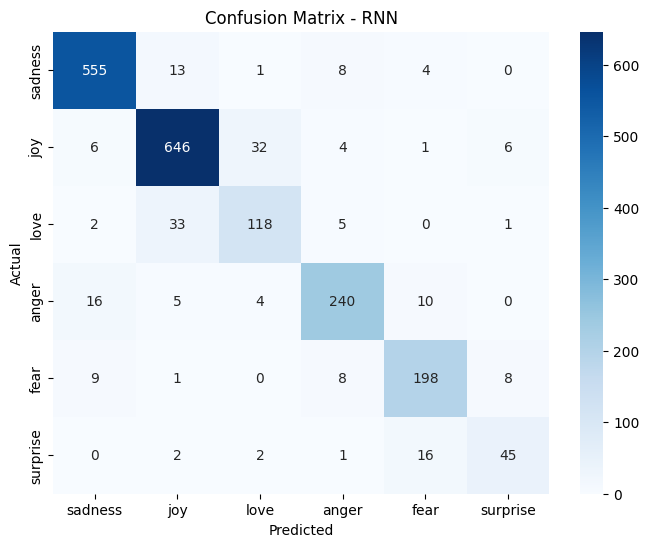

In [23]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names,
            yticklabels=label_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RNN")
plt.show()

## Cell 19 — Check GPU Availability

This cell checks whether CUDA is available and prints the GPU name if one exists. This is useful because transformer fine-tuning and LLM inference can be much faster on a GPU.

Knowing whether the notebook used GPU or CPU also helps explain training and inference time results in the final analysis.


In [24]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


## Cell 20 — Tokenize the Dataset for DistilBERT

This cell prepares the dataset for transformer fine-tuning. It loads the DistilBERT tokenizer and defines a tokenization function that applies truncation and padding. The tokenized dataset is then formatted so it can be used by the Hugging Face Trainer.

This is different from the RNN pipeline because DistilBERT expects subword token IDs and attention masks. The attention mask tells the model which tokens are real and which positions are padding.


In [25]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import evaluate

MODEL_NAME = "distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def bert_tokenize(batch):
    return bert_tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

encoded_dataset = dataset.map(bert_tokenize, batched=True)

encoded_dataset = encoded_dataset.rename_column("label", "labels")
encoded_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

## Cell 21 — Confirm the Device for Transformer Training

This cell prints the device that will be used for DistilBERT training. If CUDA is available, the model runs on GPU; otherwise, it runs on CPU.

This matters because transformer models contain many more parameters than the RNN baseline, so the available device strongly affects training time.


In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## Cell 22 — Load DistilBERT with a Classification Head

This cell loads `distilbert-base-uncased` with a sequence classification head for six emotion classes. DistilBERT is a pretrained transformer encoder, meaning it already learned general English language patterns before being fine-tuned on this specific task.

The cell also counts the total and trainable parameters. `distilbert-base-uncased` has around 67 million parameters, and in this notebook all of them are trainable because the full model is fine-tuned, not only the final classification layer.

DistilBERT was pretrained using knowledge distillation from BERT and a masked-language-modeling-style objective, where the model learns to understand missing words from context. This helps compared to the from-scratch RNN because DistilBERT starts with general language knowledge, while the RNN must learn word meanings, context, and the emotion classification task only from the labeled training data.


In [27]:
MODEL_NAME = "distilbert-base-uncased"

model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6
).to(device)

total_params = sum(p.numel() for p in model_bert.parameters())
trainable_params = sum(p.numel() for p in model_bert.parameters() if p.requires_grad)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 66958086
Trainable parameters: 66958086


## Cell 23 — Define Evaluation Metrics for the Transformer

This cell defines the metric function used by the Hugging Face Trainer. It converts the model logits into predicted class IDs and calculates accuracy and macro F1.

Using the same metrics as the RNN makes the comparison fair. Both models are evaluated on the same test set using the same scoring methods.


In [28]:
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    acc = accuracy_metric.compute(predictions=preds, references=labels)["accuracy"]
    macro_f1 = f1_metric.compute(
        predictions=preds,
        references=labels,
        average="macro"
    )["f1"]

    return {
        "accuracy": acc,
        "macro_f1": macro_f1
    }

## Cell 24 — Configure the DistilBERT Trainer

This cell sets the training configuration for fine-tuning DistilBERT. It defines the learning rate, batch sizes, number of epochs, evaluation strategy, weight decay, and logging behavior.

The learning rate is small because pretrained transformer weights should be updated carefully. A large learning rate could damage the useful knowledge already learned during pretraining.

The full DistilBERT model is fine-tuned for 2 epochs, which matches the assignment requirement of using 2–3 epochs for the transfer-learning experiment.


In [29]:
training_args = TrainingArguments(
    output_dir="./distilbert_fast",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=100,
    fp16=True
)

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    compute_metrics=compute_metrics
)


## Cell 25 — Fine-Tune DistilBERT and Measure Training Time

This cell starts the DistilBERT fine-tuning process and measures how long it takes. During fine-tuning, the model adapts its pretrained language understanding to the emotion classification task.

The training time is saved so it can be compared with the RNN training time and the LLM prompting inference time in the final analysis.


In [30]:
bert_train_start = time.time()

trainer.train()

bert_train_time = time.time() - bert_train_start

print(f"DistilBERT training time: {bert_train_time:.2f} seconds")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.231631,0.185481,0.932500,0.908885
2,0.134432,0.148738,0.940000,0.916235


DistilBERT training time: 103.86 seconds


## Cell 26 — Evaluate DistilBERT on the Test Set

This cell uses the fine-tuned DistilBERT model to predict labels for the test set. It measures inference time, extracts predicted labels, and calculates accuracy, macro F1, and the full classification report.

This produces the final transformer results for comparison with the RNN and LLM prompting methods.


In [31]:
bert_test_start = time.time()

predictions = trainer.predict(encoded_dataset["test"])

bert_test_time = time.time() - bert_test_start

bert_preds = np.argmax(predictions.predictions, axis=1)
bert_labels = predictions.label_ids

bert_acc = accuracy_score(bert_labels, bert_preds)
bert_macro_f1 = f1_score(bert_labels, bert_preds, average="macro")

print(f"DistilBERT Test Inference Time: {bert_test_time:.2f} seconds")
print(f"DistilBERT Test Accuracy: {bert_acc:.4f}")
print(f"DistilBERT Macro F1: {bert_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(bert_labels, bert_preds, target_names=label_names))

DistilBERT Test Inference Time: 1.78 seconds
DistilBERT Test Accuracy: 0.9240
DistilBERT Macro F1: 0.8766

Classification Report:
              precision    recall  f1-score   support

     sadness       0.96      0.96      0.96       581
         joy       0.95      0.95      0.95       695
        love       0.82      0.86      0.84       159
       anger       0.92      0.92      0.92       275
        fear       0.88      0.88      0.88       224
    surprise       0.75      0.68      0.71        66

    accuracy                           0.92      2000
   macro avg       0.88      0.87      0.88      2000
weighted avg       0.92      0.92      0.92      2000



## Cell 27 — Display the DistilBERT Confusion Matrix

This cell visualizes DistilBERT's prediction errors using a confusion matrix. It shows which emotions are classified correctly and which emotions are confused with each other.

This matrix is later used in the failure-mode discussion to compare how DistilBERT's mistakes differ from the RNN and LLM mistakes.


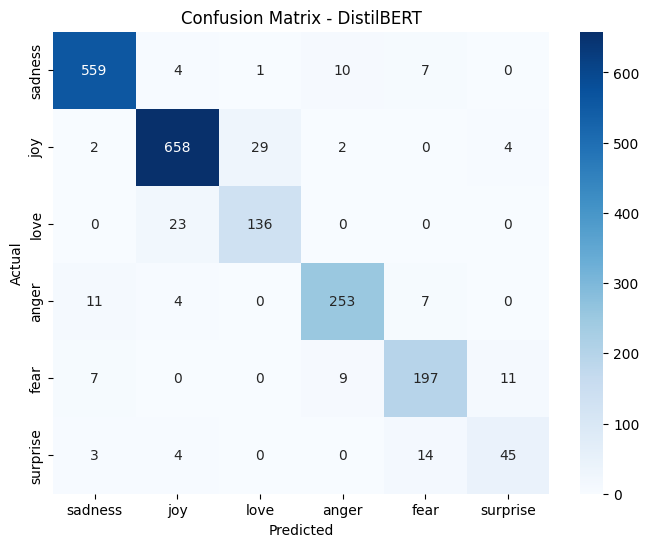

In [32]:
cm = confusion_matrix(bert_labels, bert_preds)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - DistilBERT")
plt.show()

## Cell 28 — Load the Instruction-Tuned LLM

This cell loads `google/flan-t5-small`, an instruction-tuned sequence-to-sequence language model. Unlike the RNN and DistilBERT models, this model is not trained or fine-tuned on the emotion dataset in this notebook.

FLAN-T5 is based on the T5 encoder-decoder transformer architecture. T5 treats many NLP tasks as text-to-text problems, where both the input and output are text. It was pretrained using a span-corruption objective, where parts of the input text are masked and the model learns to generate the missing spans. FLAN-T5 was then instruction-tuned on many tasks so it can better follow natural-language prompts.

In this project, FLAN-T5 is used through prompting only. The input is written as an instruction, and the model generates a text answer. This allows emotion classification without gradient updates, which represents the LLM prompting paradigm.


In [33]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch, time

LLM_MODEL = "google/flan-t5-small"

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)
llm_model = AutoModelForSeq2SeqLM.from_pretrained(LLM_MODEL).to(device)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

# Cell 29 — Select the Test Set for LLM Prompting

This cell selects the full test set for LLM evaluation.

The same test split is used across all prompting strategies
(Zero-shot, Few-shot, and Chain-of-Thought) to ensure fair
comparison between the different learning paradigms.

In [34]:
test_subset = dataset["test"].select(range(2000))

## Cell 30 — Create Label Mapping Dictionaries

This cell creates two dictionaries: one mapping numeric label IDs to emotion names, and another mapping emotion names back to IDs.

These mappings are needed because the LLM outputs text labels such as `joy` or `sadness`, while the evaluation metrics require numeric labels. The mapping makes it possible to compare generated LLM outputs with the true dataset labels.


In [35]:
id2label = {i: label for i, label in enumerate(label_names)}
label2id = {v: k for k, v in id2label.items()}

## Cell 31 — Define the Zero-Shot Prompt

This cell defines the zero-shot prompt template. In zero-shot prompting, the LLM receives only the task instruction and the input text. It does not receive any labeled examples.

The prompt asks the model to choose one of the six emotion labels and answer with only one word. This makes the generated output easier to parse and evaluate automatically.


In [36]:
def zero_shot_prompt(text):
    return f"""
Classify the emotion of this text into one of:
joy, sadness, anger, fear, love, surprise.

Text: "{text}"

Answer with ONLY one word:
"""

## Cell 32 — Define the LLM Prediction Function

This cell defines a helper function that sends a prompt to the FLAN-T5 model and decodes the generated response. The function tokenizes the prompt, passes it to the model, generates a short output, and converts the output IDs back into text.

The maximum number of generated tokens is kept small because the expected answer is only one emotion label. This reduces inference time and makes parsing simpler.


In [37]:
def get_llm_prediction(prompt):
    inputs = llm_tokenizer(prompt, return_tensors="pt", truncation=True).to(device)

    outputs = llm_model.generate(
        **inputs,
        max_new_tokens=5
    )

    return llm_tokenizer.decode(outputs[0], skip_special_tokens=True).lower()

## Cell 33 — Evaluate Zero-Shot LLM Prompting

This cell evaluates the zero-shot prompting approach on the selected test subset. For each example, the prompt is created, the LLM generates an answer, and the output is matched to one of the valid emotion labels.

The cell calculates accuracy, macro F1, and total inference time. These results show how well the LLM can perform without any task-specific training examples.


In [38]:
llm_preds = []
llm_labels = []

start = time.time()

for example in test_subset:
    output = get_llm_prediction(zero_shot_prompt(example["text"]))

    pred = None
    for label in label_names:
        if label in output:
            pred = label
            break

    if pred is None:
        pred = "joy"

    llm_preds.append(label2id[pred])
    llm_labels.append(example["label"])

llm_zero_time = time.time() - start

print("Zero-shot inference time:", llm_zero_time)
print("Accuracy:", accuracy_score(llm_labels, llm_preds))
print("Macro F1:", f1_score(llm_labels, llm_preds, average="macro"))

Zero-shot inference time: 92.29759192466736
Accuracy: 0.5565
Macro F1: 0.5304057773131596


## Cell 34 — Display the Zero-Shot LLM Confusion Matrix

This cell creates a confusion matrix for the zero-shot LLM results. It shows the emotions that the LLM predicts correctly and the emotions it confuses.

This is useful because LLM prompting may make different types of errors than trained classifiers. For example, it may default to common emotions or misread short ambiguous texts.


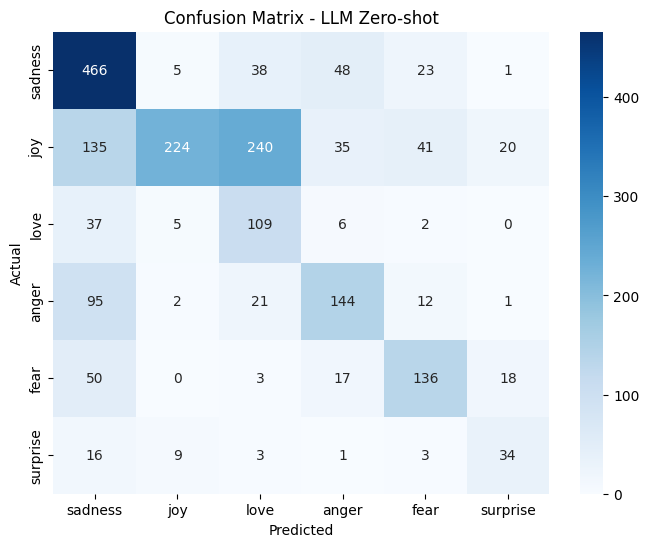

In [39]:
cm = confusion_matrix(llm_labels, llm_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names,
            yticklabels=label_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - LLM Zero-shot")
plt.show()

## Cell 35 — Show Example Zero-Shot Prompts and Raw Outputs

This cell prints several zero-shot prompts along with the raw outputs generated by the LLM and the true labels. This is important because prompting experiments should not only report metrics; they should also show how the model was instructed and what it actually produced.

The raw outputs help verify whether the prompt format is working and whether the model is following the instruction to return only one emotion label.


In [40]:
for i in range(5):
    text = test_subset[i]["text"]
    prompt = zero_shot_prompt(text)
    output = get_llm_prediction(prompt)

    print("="*80)
    print("PROMPT:")
    print(prompt)
    print("RAW OUTPUT:")
    print(output)
    print("TRUE LABEL:", id2label[test_subset[i]["label"]])

PROMPT:

Classify the emotion of this text into one of:
joy, sadness, anger, fear, love, surprise.

Text: "im feeling rather rotten so im not very ambitious right now"

Answer with ONLY one word:

RAW OUTPUT:
sadness
TRUE LABEL: sadness
PROMPT:

Classify the emotion of this text into one of:
joy, sadness, anger, fear, love, surprise.

Text: "im updating my blog because i feel shitty"

Answer with ONLY one word:

RAW OUTPUT:
sadness
TRUE LABEL: sadness
PROMPT:

Classify the emotion of this text into one of:
joy, sadness, anger, fear, love, surprise.

Text: "i never make her separate from me because i don t ever want her to feel like i m ashamed with her"

Answer with ONLY one word:

RAW OUTPUT:
sadness
TRUE LABEL: sadness
PROMPT:

Classify the emotion of this text into one of:
joy, sadness, anger, fear, love, surprise.

Text: "i left with my bouquet of red and yellow tulips under my arm feeling slightly more optimistic than when i arrived"

Answer with ONLY one word:

RAW OUTPUT:
joy
TR

## Cell 36 — Define the 3-Shot Prompt

This cell defines a few-shot prompt with three labeled examples. Few-shot prompting gives the LLM examples of the expected input-output format before asking it to classify the new text.

The purpose is to test whether a small number of demonstrations helps the LLM understand the task better than zero-shot prompting.


In [41]:
def few_shot_prompt_3(text):
    return f"""
Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Now classify:
Text: {text}
Emotion:
"""

## Cell 37 — Evaluate the 3-Shot LLM Prompt

This cell evaluates the LLM using the 3-shot prompt on the selected test subset. The same parsing and metric calculation process is used as in the zero-shot setting.

Comparing this result with zero-shot performance shows whether adding a few examples improves emotion classification accuracy and macro F1.


In [42]:
few3_preds = []
few3_labels = []

start = time.time()

for example in test_subset:
    output = get_llm_prediction(few_shot_prompt_3(example["text"]))

    pred = None
    for label in label_names:
        if label in output:
            pred = label
            break

    if pred is None:
        pred = "joy"

    few3_preds.append(label2id[pred])
    few3_labels.append(example["label"])

few3_time = time.time() - start

print("Few-shot 3 inference time:", few3_time)
print("Accuracy:", accuracy_score(few3_labels, few3_preds))
print("Macro F1:", f1_score(few3_labels, few3_preds, average="macro"))

Few-shot 3 inference time: 84.40385818481445
Accuracy: 0.532
Macro F1: 0.4909637706951527


## 3-Shot LLM Confusion Matrix

This cell displays the confusion matrix for the 3-shot prompting setting.


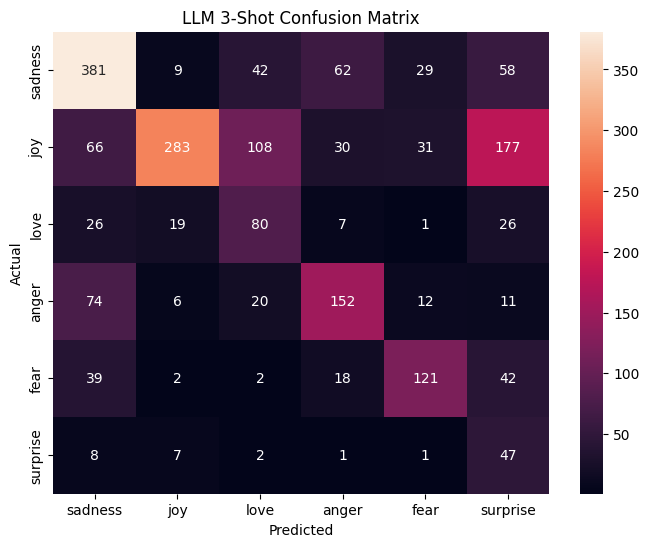

In [43]:
cm = confusion_matrix(few3_labels, few3_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=label_names, yticklabels=label_names)
plt.title("LLM 3-Shot Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Show Example 3-Shot Prompts and Raw Outputs

This cell prints example 3-shot prompts and the raw model outputs so the prompting behavior can be inspected.


In [44]:
for i in range(3):
    text = test_subset[i]["text"]
    prompt = few_shot_prompt_3(text)
    raw_output = get_llm_prediction(prompt)

    print("=" * 80)
    print("PROMPT:")
    print(prompt)
    print("\nRAW MODEL OUTPUT:")
    print(raw_output)


PROMPT:

Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Now classify:
Text: im feeling rather rotten so im not very ambitious right now
Emotion:


RAW MODEL OUTPUT:
sadness
PROMPT:

Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Now classify:
Text: im updating my blog because i feel shitty
Emotion:


RAW MODEL OUTPUT:
sadness
PROMPT:

Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Now classify:
Text: i never make her sep

## Cell 38 — Define the 8-Shot Prompt

This cell defines a larger few-shot prompt with eight labeled examples. The idea is to give the LLM more demonstrations of how text should be mapped to emotion labels.

This tests whether increasing the number of examples in the prompt improves performance or whether the longer prompt adds noise and does not help much.


In [45]:
def few_shot_prompt_8(text):
    return f"""
Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Text: i am furious about what happened
Emotion: anger

Text: i feel so much affection for my family
Emotion: love

Text: i was shocked by the news
Emotion: surprise

Text: i feel cheerful and excited
Emotion: joy

Text: i feel disappointed and low
Emotion: sadness

Now classify:
Text: {text}
Emotion:
"""

## Cell 39 — Evaluate the 8-Shot LLM Prompt

This cell evaluates the LLM using the 8-shot prompt. It loops through the selected test subset, generates an output for each text, parses the predicted emotion, and calculates performance metrics.

The result is compared with both zero-shot and 3-shot prompting to understand the effect of adding more examples to the prompt.


In [46]:
few8_preds = []
few8_labels = []

start = time.time()

for example in test_subset:
    output = get_llm_prediction(few_shot_prompt_8(example["text"]))

    pred = None
    for label in label_names:
        if label in output:
            pred = label
            break

    if pred is None:
        pred = "joy"

    few8_preds.append(label2id[pred])
    few8_labels.append(example["label"])

few8_time = time.time() - start

print("Few-shot 8 inference time:", few8_time)
print("Accuracy:", accuracy_score(few8_labels, few8_preds))
print("Macro F1:", f1_score(few8_labels, few8_preds, average="macro"))

Few-shot 8 inference time: 86.10641765594482
Accuracy: 0.577
Macro F1: 0.522750727191202


## 8-Shot LLM Confusion Matrix

This cell displays the confusion matrix for the 8-shot prompting setting.


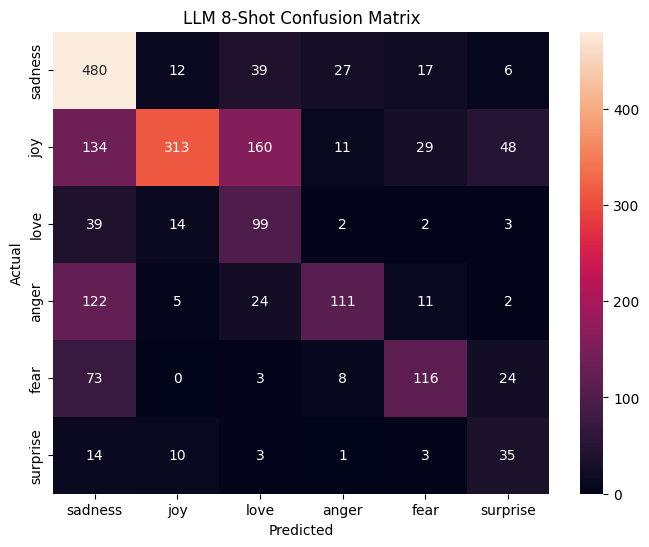

In [47]:
cm = confusion_matrix(few8_labels, few8_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=label_names, yticklabels=label_names)
plt.title("LLM 8-Shot Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Cell 40 — Show Example 8-Shot Prompts and Raw Outputs

This cell prints example 8-shot prompts and the model's raw generated outputs. This helps demonstrate exactly how few-shot prompting was implemented.

Showing raw outputs is useful because LLMs may sometimes generate extra words or unexpected formatting. These examples make the evaluation process more transparent.


In [48]:
for i in range(3):
    text = test_subset[i]["text"]
    prompt = few_shot_prompt_8(text)
    output = get_llm_prediction(prompt)

    print("="*80)
    print("PROMPT:")
    print(prompt)
    print("RAW OUTPUT:")
    print(output)
    print("TRUE LABEL:", id2label[test_subset[i]["label"]])

PROMPT:

Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Text: i am furious about what happened
Emotion: anger

Text: i feel so much affection for my family
Emotion: love

Text: i was shocked by the news
Emotion: surprise

Text: i feel cheerful and excited
Emotion: joy

Text: i feel disappointed and low
Emotion: sadness

Now classify:
Text: im feeling rather rotten so im not very ambitious right now
Emotion:

RAW OUTPUT:
sadness
TRUE LABEL: sadness
PROMPT:

Classify the emotion as one of: sadness, joy, love, anger, fear, surprise.

Examples:
Text: i feel very happy today
Emotion: joy

Text: i feel so alone and empty
Emotion: sadness

Text: i am scared something bad will happen
Emotion: fear

Text: i am furious about what happened
Emotion: anger

Text: i feel so much affection for my family
Emotion:

## Cell 41 — Define the Chain-of-Thought Prompt

This cell defines a chain-of-thought style prompt. Instead of asking only for the final label, the prompt asks the model to briefly reason about the emotion before giving the final answer.

The goal is to test whether encouraging reasoning improves classification. However, because the evaluation needs a final label, the generated response still has to be parsed carefully.


In [49]:
def cot_prompt(text):
    return f"""
Classify the emotion step by step.

Text: {text}

First explain the emotion briefly, then give the final answer as one word:
"""

## Cell 42 — Evaluate Chain-of-Thought Prompting

This cell evaluates the LLM using the chain-of-thought prompt. The model generates a response that may include reasoning and a final emotion label. The code then searches the output for one of the valid emotion labels.

This result is compared with zero-shot and few-shot prompting to see whether reasoning-style prompting improves or hurts performance on short emotion classification texts.


In [51]:
cot_preds = []
cot_labels = []

start = time.time()

for example in test_subset:
    output = get_llm_prediction(cot_prompt(example["text"]))

    pred = None
    for label in label_names:
        if label in output:
            pred = label
            break

    if pred is None:
        pred = "joy"

    cot_preds.append(label2id[pred])
    cot_labels.append(example["label"])

cot_time = time.time() - start

print("CoT inference time:", cot_time)
print("Accuracy:", accuracy_score(cot_labels, cot_preds))
print("Macro F1:", f1_score(cot_labels, cot_preds, average="macro"))

CoT inference time: 91.19723010063171
Accuracy: 0.3495
Macro F1: 0.09194385372531831


## Chain-of-Thought LLM Confusion Matrix

This cell displays the confusion matrix for the chain-of-thought prompting setting.


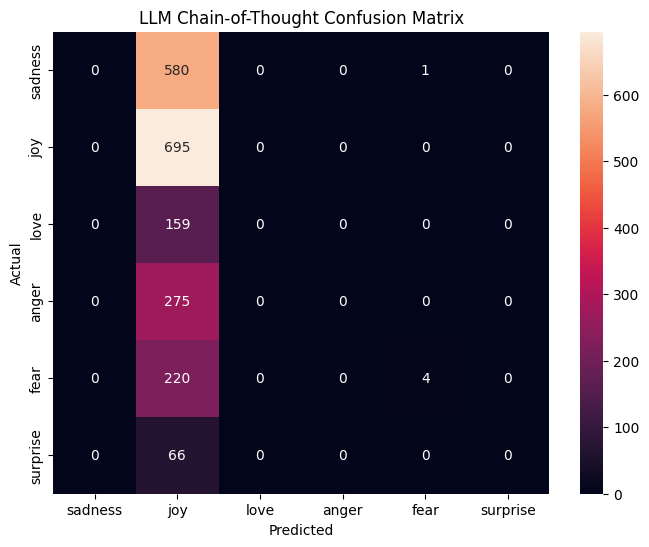

In [52]:
cm = confusion_matrix(cot_labels, cot_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=label_names, yticklabels=label_names)
plt.title("LLM Chain-of-Thought Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Cell 43 — Show Example Chain-of-Thought Prompts and Outputs

This cell prints example chain-of-thought prompts, raw model outputs, and true labels. These examples help show whether the model is actually reasoning in a useful way or simply producing a label.

They also help identify possible parsing problems, such as the model mentioning multiple emotions in one answer.


In [53]:
for i in range(3):
    text = test_subset[i]["text"]
    prompt = cot_prompt(text)
    output = get_llm_prediction(prompt)

    print("="*80)
    print("PROMPT:")
    print(prompt)
    print("RAW OUTPUT:")
    print(output)
    print("TRUE LABEL:", id2label[test_subset[i]["label"]])

PROMPT:

Classify the emotion step by step.

Text: im feeling rather rotten so im not very ambitious right now

First explain the emotion briefly, then give the final answer as one word:

RAW OUTPUT:
step
TRUE LABEL: sadness
PROMPT:

Classify the emotion step by step.

Text: im updating my blog because i feel shitty

First explain the emotion briefly, then give the final answer as one word:

RAW OUTPUT:
step
TRUE LABEL: sadness
PROMPT:

Classify the emotion step by step.

Text: i never make her separate from me because i don t ever want her to feel like i m ashamed with her

First explain the emotion briefly, then give the final answer as one word:

RAW OUTPUT:
emotion
TRUE LABEL: sadness


## Cell 44 — Create a Balanced 500-Example Training Subset

This cell constructs the small training subset required for the data efficiency experiment. It shuffles the training data and selects examples from each emotion class to create a roughly balanced subset of about 500 examples.

This experiment is important because it tests how models behave when labeled data is limited. It helps reveal the value of pretraining: pretrained models usually need less task-specific data than models trained from scratch.


In [55]:
from datasets import concatenate_datasets

small_train_shuffled = dataset["train"].shuffle(seed=42)

splits = []

# 500 examples balanced as closely as possible across 6 classes:
# 84 + 84 + 83 + 83 + 83 + 83 = 500
samples_per_class = {
    0: 84,
    1: 84,
    2: 83,
    3: 83,
    4: 83,
    5: 83
}

for label_id, n_samples in samples_per_class.items():
    class_subset = small_train_shuffled.filter(lambda x: x["label"] == label_id).select(range(n_samples))
    splits.append(class_subset)

small_train = concatenate_datasets(splits).shuffle(seed=42)

print("Small training subset size:", len(small_train))
print("Class distribution:")
print(pd.Series(small_train["label"]).value_counts().sort_index())


Small training subset size: 500
Class distribution:
0    84
1    84
2    83
3    83
4    83
5    83
Name: count, dtype: int64


## Cell 45 — Tokenize the Small Subset for DistilBERT

This cell tokenizes the balanced 500-example subset using the same DistilBERT tokenizer as before. The labels are renamed and the dataset is formatted for PyTorch so it can be used by the Hugging Face Trainer.

Using the same preprocessing pipeline ensures that the small-data transformer experiment is comparable to the full-data transformer experiment.


In [56]:
small_encoded = small_train.map(bert_tokenize, batched=True)
small_encoded = small_encoded.rename_column("label", "labels")
small_encoded.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

## Cell 46 — Fine-Tune DistilBERT on the Small Subset

This cell initializes a new DistilBERT classification model and fine-tunes it only on the small balanced subset. This is separate from the full-data DistilBERT model so the experiment measures performance when only limited labeled data is available.

The result helps demonstrate the advantage of transfer learning: even with fewer examples, the pretrained transformer may still perform reasonably because it already has general language knowledge.


In [57]:
small_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6
).to(device)

small_training_args = TrainingArguments(
    output_dir="./bert_small",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=15,
    fp16=True
)

small_trainer = Trainer(
    model=small_model,
    args=small_training_args,
    train_dataset=small_encoded,
    eval_dataset=encoded_dataset["validation"],
    compute_metrics=compute_metrics
)

small_train_start = time.time()

small_trainer.train()

small_train_time = time.time() - small_train_start

print(f"Small DistilBERT training time: {small_train_time:.2f} seconds")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,1.766553,0.281500,0.131063
2,No log,1.742831,0.250000,0.212573
3,No log,1.619181,0.425000,0.397494
4,No log,1.369987,0.612500,0.554237
5,No log,1.099588,0.670500,0.612024
6,No log,0.956100,0.715000,0.665745
7,No log,0.866688,0.705000,0.663973
8,No log,0.797277,0.721000,0.675937
9,No log,0.768907,0.724500,0.693696
10,No log,0.681960,0.767000,0.732992


Small DistilBERT training time: 52.91 seconds


## Cell 47 — Evaluate the Small-Data DistilBERT Model

This cell evaluates the DistilBERT model that was fine-tuned on only the small 500-example subset. It predicts labels on the test set and calculates accuracy.

This accuracy is later compared with the full-data DistilBERT result and the RNN result to show how performance changes when the amount of labeled training data is reduced.


In [58]:
small_bert_test_start = time.time()

preds = small_trainer.predict(encoded_dataset["test"])

small_bert_test_time = time.time() - small_bert_test_start

small_preds = np.argmax(preds.predictions, axis=1)
small_labels = preds.label_ids

small_acc = accuracy_score(small_labels, small_preds)
small_macro_f1 = f1_score(small_labels, small_preds, average="macro")

print(f"Small DistilBERT Test Accuracy: {small_acc:.4f}")
print(f"Small DistilBERT Macro F1: {small_macro_f1:.4f}")
print(f"Small DistilBERT Test Inference Time: {small_bert_test_time:.2f} seconds")


Small DistilBERT Test Accuracy: 0.7510
Small DistilBERT Macro F1: 0.7033
Small DistilBERT Test Inference Time: 1.67 seconds


## Retrain the RNN on the 500-Example Subset

This cell repeats the from-scratch RNN experiment using only the balanced 500-example training subset. This is required for the data efficiency experiment because the project compares how the RNN and DistilBERT behave when labeled training data is limited.

Unlike DistilBERT, the RNN has no pretrained language knowledge. Therefore, reducing the training data is expected to hurt the RNN more strongly.


In [59]:
# Prepare the small 500-example subset for the RNN
small_train_X, small_train_y = prepare_data(small_train, vocab, MAX_LENGTH)

small_rnn_dataset = TensorDataset(small_train_X, small_train_y)
small_rnn_loader = DataLoader(small_rnn_dataset, batch_size=BATCH_SIZE, shuffle=True)

# Create a fresh RNN model for the small-data experiment
small_rnn_model = LSTMClassifier(len(vocab), EMBEDDING_DIM, HIDDEN_DIM, NUM_CLASSES).to(device)

small_rnn_optimizer = torch.optim.Adam(small_rnn_model.parameters(), lr=0.001)

small_rnn_train_losses = []
small_rnn_val_losses = []

SMALL_RNN_EPOCHS = 15

small_rnn_train_start = time.time()

for epoch in range(SMALL_RNN_EPOCHS):
    train_loss, train_acc = train_epoch(
        small_rnn_model,
        small_rnn_loader,
        criterion,
        small_rnn_optimizer,
        device
    )

    val_loss, val_acc = evaluate_rnn(
        small_rnn_model,
        val_loader,
        criterion,
        device
    )

    small_rnn_train_losses.append(train_loss)
    small_rnn_val_losses.append(val_loss)

    print(f"Epoch {epoch+1}")
    print(f"Small RNN Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f} | Validation Acc: {val_acc:.4f}\n")

small_rnn_train_time = time.time() - small_rnn_train_start

print(f"Small RNN Training Time: {small_rnn_train_time:.2f} seconds")


Epoch 1
Small RNN Train Loss: 1.7964 | Train Acc: 0.1640
Validation Loss: 1.7990 | Validation Acc: 0.1255

Epoch 2
Small RNN Train Loss: 1.7851 | Train Acc: 0.2120
Validation Loss: 1.7805 | Validation Acc: 0.2625

Epoch 3
Small RNN Train Loss: 1.7664 | Train Acc: 0.2960
Validation Loss: 1.7913 | Validation Acc: 0.1935

Epoch 4
Small RNN Train Loss: 1.7138 | Train Acc: 0.3000
Validation Loss: 1.7641 | Validation Acc: 0.2845

Epoch 5
Small RNN Train Loss: 1.5488 | Train Acc: 0.3880
Validation Loss: 1.9487 | Validation Acc: 0.1870

Epoch 6
Small RNN Train Loss: 1.2662 | Train Acc: 0.5460
Validation Loss: 2.0639 | Validation Acc: 0.2355

Epoch 7
Small RNN Train Loss: 0.9418 | Train Acc: 0.6760
Validation Loss: 2.2311 | Validation Acc: 0.2305

Epoch 8
Small RNN Train Loss: 0.5990 | Train Acc: 0.8180
Validation Loss: 2.4885 | Validation Acc: 0.2225

Epoch 9
Small RNN Train Loss: 0.3849 | Train Acc: 0.8860
Validation Loss: 2.6965 | Validation Acc: 0.2585

Epoch 10
Small RNN Train Loss: 0.1726

## Evaluate the Small-Data RNN on the Test Set

This cell evaluates the RNN trained only on the 500-example subset. The result is compared with the full-data RNN and the small-data DistilBERT model to show the effect of reducing the amount of labeled training data.


In [60]:
small_rnn_model.eval()

small_rnn_preds = []
small_rnn_labels = []

small_rnn_test_start = time.time()

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        outputs = small_rnn_model(batch_x)

        _, preds = torch.max(outputs, 1)

        small_rnn_preds.extend(preds.cpu().numpy())
        small_rnn_labels.extend(batch_y.numpy())

small_rnn_test_time = time.time() - small_rnn_test_start

small_rnn_acc = accuracy_score(small_rnn_labels, small_rnn_preds)
small_rnn_f1 = f1_score(small_rnn_labels, small_rnn_preds, average="macro")

print(f"Small RNN Test Accuracy: {small_rnn_acc:.4f}")
print(f"Small RNN Macro F1: {small_rnn_f1:.4f}")
print(f"Small RNN Test Inference Time: {small_rnn_test_time:.2f} seconds")


Small RNN Test Accuracy: 0.2180
Small RNN Macro F1: 0.2039
Small RNN Test Inference Time: 0.22 seconds


## Cell 48 — Automatically Compute Final Metrics

This cell collects the final metrics from the different experiments and computes them in one place. It includes the RNN results, full DistilBERT results, LLM prompting results, and small-data experiment values where available.

This is useful because the final comparison table and plots should be generated automatically from the stored variables instead of manually typing results. This reduces the risk of copying wrong numbers into the report.


In [61]:
# Automatically compute all final metrics

# RNN full-data results
rnn_acc = accuracy_score(all_labels, all_preds)
rnn_macro_f1 = f1_score(all_labels, all_preds, average="macro")

# Full DistilBERT results
bert_acc = accuracy_score(bert_labels, bert_preds)
bert_macro_f1 = f1_score(bert_labels, bert_preds, average="macro")

# LLM zero-shot results
llm_acc = accuracy_score(llm_labels, llm_preds)
llm_f1 = f1_score(llm_labels, llm_preds, average="macro")

# LLM few-shot 3 results
few3_acc = accuracy_score(few3_labels, few3_preds)
few3_f1 = f1_score(few3_labels, few3_preds, average="macro")

# LLM few-shot 8 results
few8_acc = accuracy_score(few8_labels, few8_preds)
few8_f1 = f1_score(few8_labels, few8_preds, average="macro")

# LLM CoT results
cot_acc = accuracy_score(cot_labels, cot_preds)
cot_f1 = f1_score(cot_labels, cot_preds, average="macro")

# Small DistilBERT 500-example results
small_bert_acc = accuracy_score(small_labels, small_preds)
small_bert_f1 = f1_score(small_labels, small_preds, average="macro")


## Cell 49 — Create the Final Results Table

This cell creates a pandas DataFrame containing the main results for all evaluated approaches. The table compares models using accuracy, macro F1, training time, and inference time.

This table directly supports the final comparative analysis because it summarizes model quality and computational cost in one place.


In [62]:
results = pd.DataFrame({
    "Model": [
        "RNN",
        "DistilBERT",
        "LLM Zero-shot",
        "LLM Few-shot 3",
        "LLM Few-shot 8",
        "LLM CoT"
    ],
    "Accuracy": [
        rnn_acc,
        bert_acc,
        llm_acc,
        few3_acc,
        few8_acc,
        cot_acc
    ],
    "Macro F1": [
        rnn_macro_f1,
        bert_macro_f1,
        llm_f1,
        few3_f1,
        few8_f1,
        cot_f1
    ],
    "Training Time (seconds)": [
        rnn_train_time,
        bert_train_time,
        0,
        0,
        0,
        0
    ],
    "Inference Time (seconds)": [
        rnn_test_time,
        bert_test_time,
        llm_zero_time,
        few3_time,
        few8_time,
        cot_time
    ]
})

results.sort_values(by="Accuracy", ascending=False)


,Model,Accuracy,Macro F1,Training Time (seconds),Inference Time (seconds)
1,DistilBERT,0.9240,0.876637,103.855658,1.778346
0,RNN,0.9010,0.849706,34.412608,0.342398
4,LLM Few-shot 8,0.5770,0.522751,0.000000,86.106418
2,LLM Zero-shot,0.5565,0.530406,0.000000,92.297592
3,LLM Few-shot 3,0.5320,0.490964,0.000000,84.403858
5,LLM CoT,0.3495,0.091944,0.000000,91.197230


## Data Efficiency Comparison Plot

This section compares model performance when only 500 labeled training examples are available versus the full training set. The LLM prompting approach is included as a no-training baseline because it does not use gradient updates.


In [63]:
data_efficiency_results = pd.DataFrame({
    "Model": [
        "RNN - 500 examples",
        "RNN - Full training set",
        "DistilBERT - 500 examples",
        "DistilBERT - Full training set",
        "LLM Prompting - No training"
    ],
    "Training Size": [
        "500",
        "Full",
        "500",
        "Full",
        "No training"
    ],
    "Test Accuracy": [
        small_rnn_acc,
        rnn_acc,
        small_bert_acc,
        bert_acc,
        llm_acc
    ]
})

data_efficiency_results


,Model,Training Size,Test Accuracy
0,RNN - 500 examples,500,0.2180
1,RNN - Full training set,Full,0.9010
2,DistilBERT - 500 examples,500,0.7510
3,DistilBERT - Full training set,Full,0.9240
4,LLM Prompting - No training,No training,0.5565


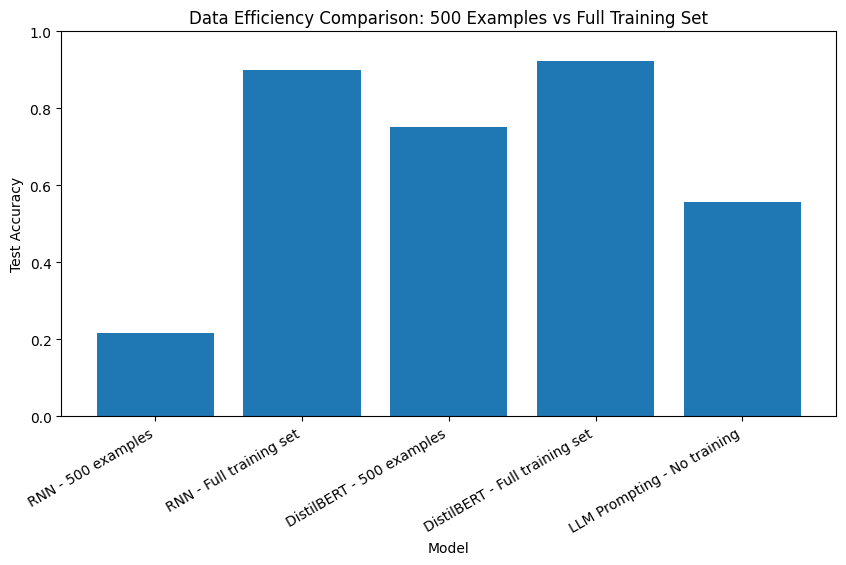

In [64]:
plt.figure(figsize=(10, 5))

plt.bar(data_efficiency_results["Model"], data_efficiency_results["Test Accuracy"])

plt.title("Data Efficiency Comparison: 500 Examples vs Full Training Set")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)

plt.show()


## Data Efficiency Discussion

The data efficiency comparison shows why pretraining is valuable. A from-scratch RNN depends heavily on the labeled training data because it learns embeddings and sequence patterns only from the task dataset. DistilBERT should usually perform better with only 500 examples because it already has pretrained language knowledge and only needs to adapt that knowledge to the emotion labels. LLM prompting requires no task-specific training, so it is useful when labeled data is limited, but it may be slower and less consistent than a fine-tuned classifier.


## Cell 50 — Identify the Best-Performing Model

This cell sorts the results by accuracy and prints the best-performing model. This gives a quick answer to which approach achieved the highest score in the experiment.

However, the best model should not be chosen based on accuracy alone. The final discussion also considers macro F1, training time, inference time, data efficiency, and practical deployment constraints.


In [65]:
best_model = results.sort_values(by="Accuracy", ascending=False).iloc[0]
print("Best Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])

Best Model: DistilBERT
Accuracy: 0.924


## Cell 51 — Plot Accuracy Comparison Across Models

This cell visualizes the accuracy of all models using a bar chart. A bar chart is useful for quickly comparing the overall correctness of each approach.

This plot helps make the final report easier to understand because readers can immediately see which models performed better or worse.


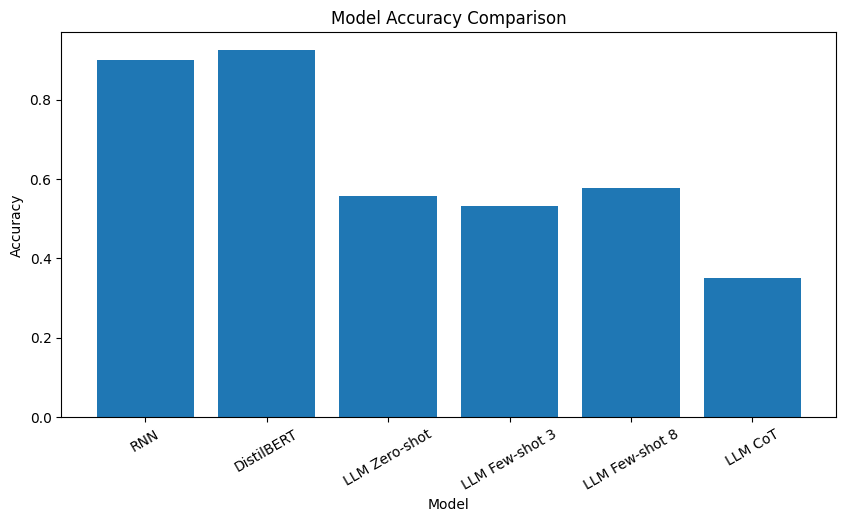

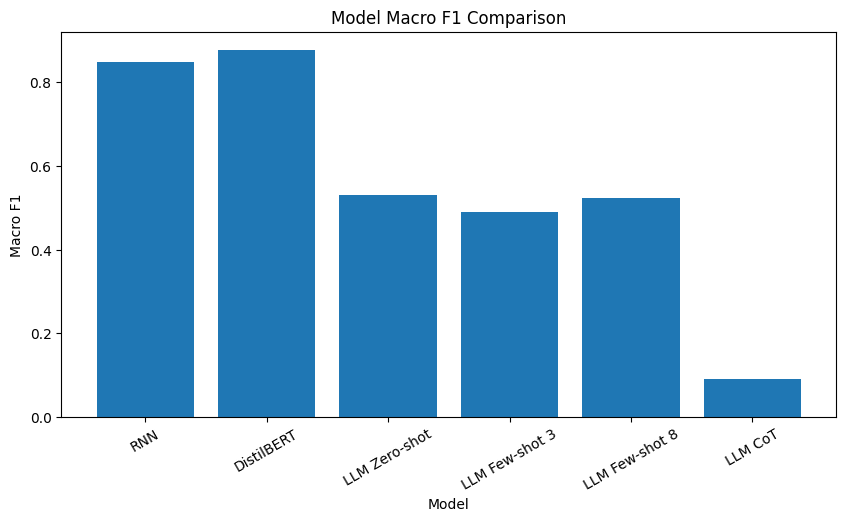

In [66]:
import matplotlib.pyplot as plt

# Accuracy plot
plt.figure(figsize=(10,5))
plt.bar(results["Model"], results["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.show()

# Macro F1 plot
plt.figure(figsize=(10,5))
plt.bar(results["Model"], results["Macro F1"])
plt.title("Model Macro F1 Comparison")
plt.xlabel("Model")
plt.ylabel("Macro F1")
plt.xticks(rotation=30)
plt.show()

## Cell 52 — Plot Accuracy and Macro F1 Together

This cell creates a grouped bar chart comparing accuracy and macro F1 for each model. This is more informative than accuracy alone because macro F1 reveals whether the model performs well across all classes.

A model with high accuracy but lower macro F1 may be doing well on common classes while struggling with less frequent or more difficult emotions.


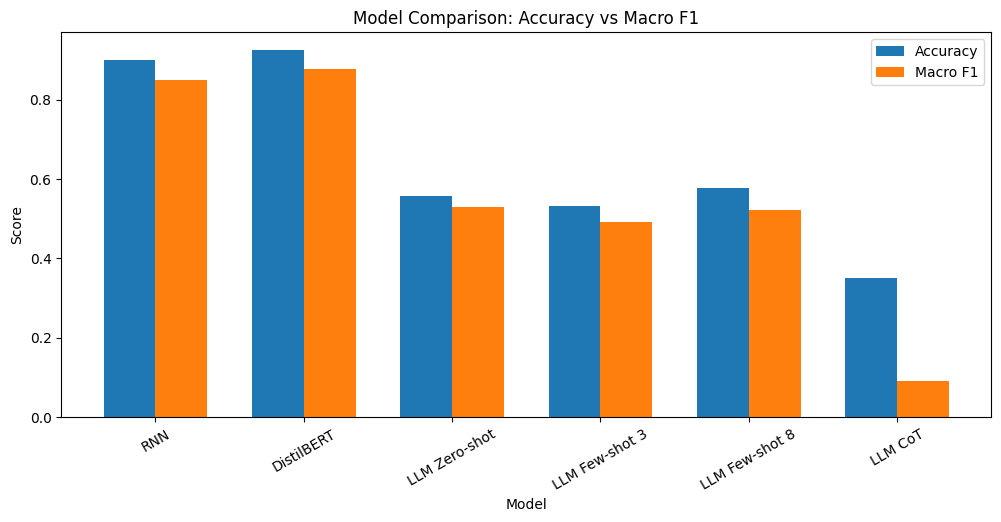

In [67]:
import numpy as np

x = np.arange(len(results["Model"]))
width = 0.35

plt.figure(figsize=(12,5))
plt.bar(x - width/2, results["Accuracy"], width, label="Accuracy")
plt.bar(x + width/2, results["Macro F1"], width, label="Macro F1")

plt.xticks(x, results["Model"], rotation=30)
plt.title("Model Comparison: Accuracy vs Macro F1")
plt.xlabel("Model")
plt.ylabel("Score")
plt.legend()
plt.show()

## Cell 53 — Plot Sorted Model Accuracy

This cell sorts the models by accuracy and displays them in a horizontal bar chart. Sorting makes the ranking easier to read than an unsorted chart.

This visualization is useful for the comparative analysis because it clearly shows the relative ordering of the approaches.


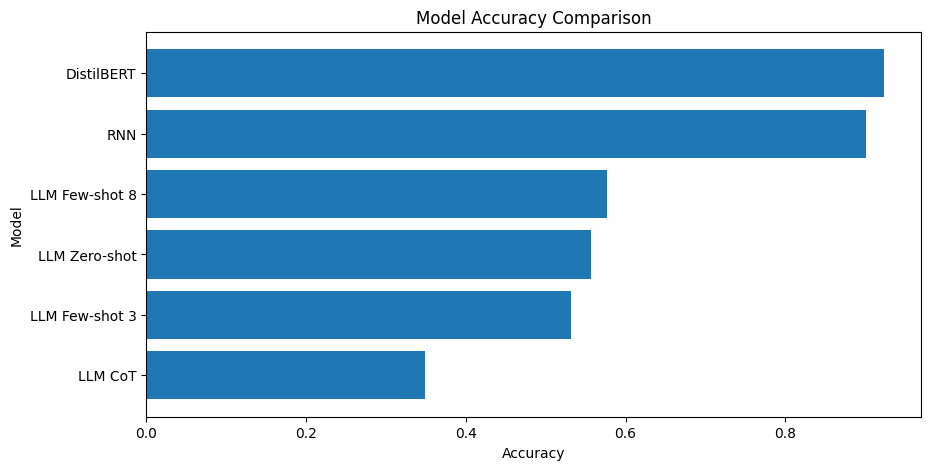

In [68]:
import matplotlib.pyplot as plt

sorted_results = results.sort_values(by="Accuracy")

plt.figure(figsize=(10,5))
plt.barh(sorted_results["Model"], sorted_results["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.show()

## Cell 54 — Plot Accuracy and Macro F1 as Lines

This cell plots accuracy and macro F1 across the models using line plots. While the models are categorical, this view can still help show how the two metrics move together across different approaches.

If accuracy and macro F1 are close, the model is likely performing consistently across classes. If they differ strongly, class-level performance should be inspected more carefully.


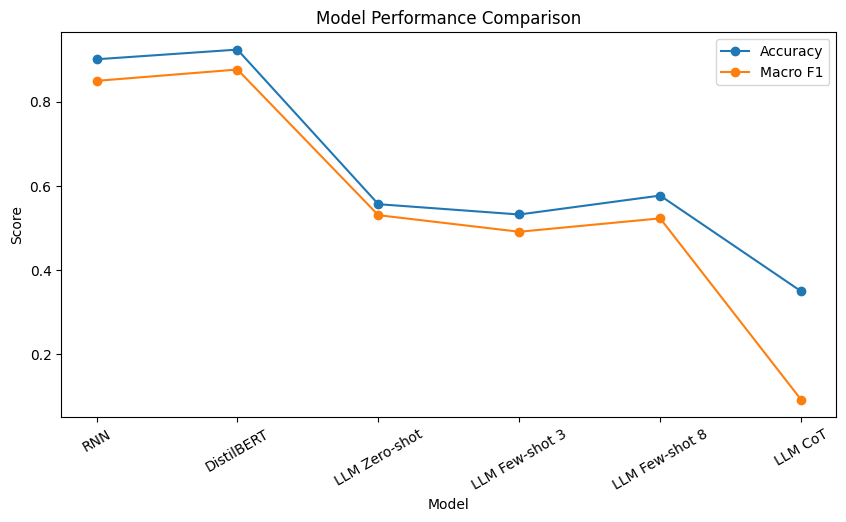

In [69]:
plt.figure(figsize=(10,5))
plt.plot(results["Model"], results["Accuracy"], marker='o', label="Accuracy")
plt.plot(results["Model"], results["Macro F1"], marker='o', label="Macro F1")

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## Cell 55 — Visualize the Relationship Between Accuracy and Macro F1

This cell creates a scatter plot where each model is represented by its accuracy and macro F1 score. Models closer to the upper-right area are stronger because they have both high overall accuracy and strong balanced class performance.

This plot helps compare models beyond a single metric and makes it easier to identify whether a model is balanced or only accurate on dominant classes.


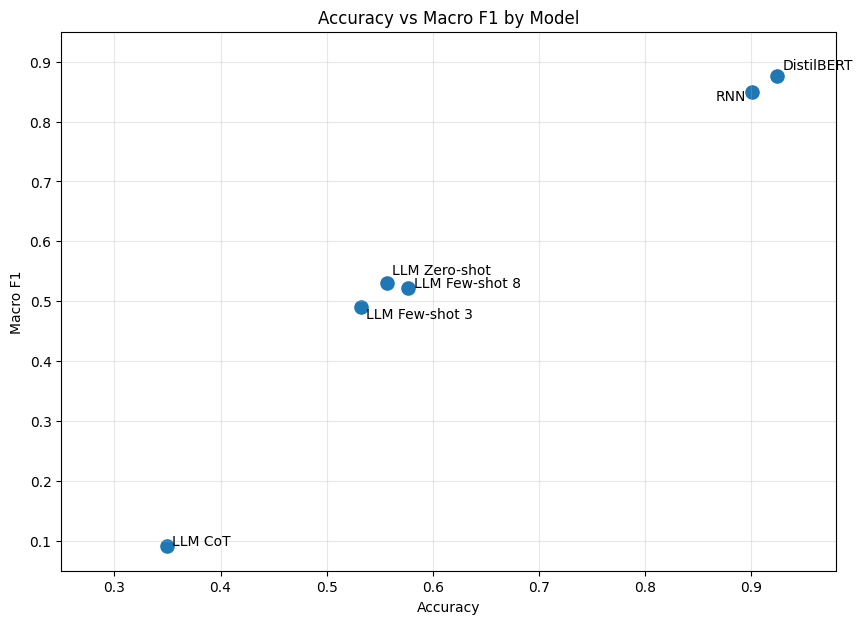

In [70]:
plt.figure(figsize=(10, 7))

plt.scatter(results["Accuracy"], results["Macro F1"], s=90)

offsets = {
    "DistilBERT": (0.005, 0.010),
    "RNN": (-0.035, -0.015),
    "LLM Zero-shot": (0.005, 0.015),
    "LLM Few-shot 3": (0.005, -0.020),
    "LLM Few-shot 8": (0.005, 0.000),
    "LLM CoT": (0.005, 0.000)
}

for i, row in results.iterrows():
    dx, dy = offsets[row["Model"]]
    plt.text(
        row["Accuracy"] + dx,
        row["Macro F1"] + dy,
        row["Model"],
        fontsize=10
    )

plt.title("Accuracy vs Macro F1 by Model")
plt.xlabel("Accuracy")
plt.ylabel("Macro F1")
plt.xlim(0.25, 0.98)
plt.ylim(0.05, 0.95)
plt.grid(True, alpha=0.3)

plt.show()

## Cell 56 — Create the Final Performance Heatmap

This cell displays the final results table as a heatmap. The heatmap gives a compact visual summary of model performance and timing values.

It is useful as the final visual comparison because it places all key metrics in one figure, making it easier to discuss the trade-offs between RNNs, fine-tuned transformers, and LLM prompting.


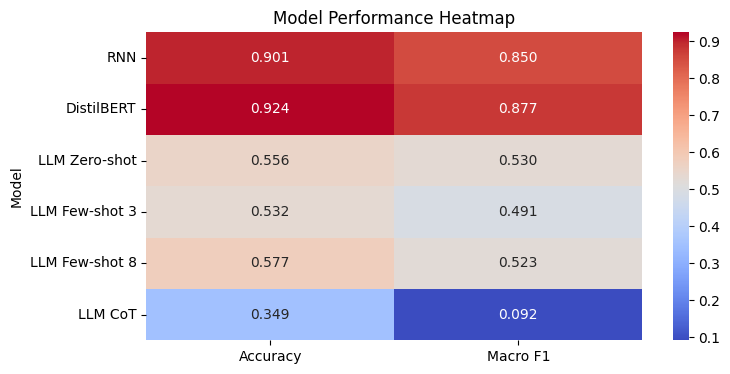

In [71]:
import seaborn as sns

plt.figure(figsize=(8, 4))
performance_metrics = results.set_index("Model")[["Accuracy", "Macro F1"]]
sns.heatmap(performance_metrics, annot=True, fmt=".3f", cmap="coolwarm")

plt.title("Model Performance Heatmap")
plt.show()


# Final Project Summary

This project compared three different NLP learning paradigms on the same six-class emotion classification task.

The first approach was a **from-scratch LSTM classifier**. It used a custom vocabulary, learned its own word embeddings from the training data, and processed text sequences using recurrent layers. This model is useful as a baseline because it shows what can be achieved when the model only learns from the labeled dataset and has no external language knowledge.

The second approach was **transfer learning with DistilBERT**. DistilBERT was already pretrained on large text corpora, so it began with general language understanding. The model was then fine-tuned on the emotion dataset using a classification head. This approach usually performs better than the RNN because it does not start from zero; it adapts existing language knowledge to the target task.

The third approach was **LLM prompting with FLAN-T5**. Instead of training or fine-tuning the model, the notebook used prompts to ask the model to classify emotions. Three prompting styles were tested: zero-shot prompting, few-shot prompting with examples, and chain-of-thought prompting. This approach is flexible because it requires no gradient updates, but it can be slower during inference and more sensitive to prompt wording.

The data efficiency experiment compared performance when only 500 balanced training examples were available. This part is important because it shows the main value of pretraining: pretrained models can often remain useful even when labeled data is limited, while models trained from scratch usually need more data to learn reliable patterns.

The final comparison used accuracy, macro F1, confusion matrices, training time, and inference time. Accuracy measures total correctness, macro F1 checks balanced class performance, confusion matrices reveal failure modes, and timing results show computational cost.


# Final Evaluation: Which Approach Should Be Used When?

In a real-world project, the best approach depends on the available data, computational resources, required accuracy, and deployment constraints.

**Use a from-scratch RNN/LSTM when:**

- the task is simple and the dataset is reasonably sized;
- the available hardware is limited;
- the goal is to build a lightweight baseline;
- interpretability and simplicity are more important than maximum performance;
- there is no need for advanced language understanding.

The disadvantage is that the RNN learns language only from the task dataset. This makes it weaker when the dataset is small or when the text contains subtle emotional meaning.

**Use a fine-tuned transformer such as DistilBERT when:**

- accuracy and macro F1 are important;
- labeled task data is available;
- the model needs strong language understanding;
- the system can afford the training and inference cost;
- the final model should be stable and consistent for production classification.

This is usually the best practical choice for supervised NLP classification because it combines pretrained language knowledge with task-specific fine-tuning.

**Use LLM prompting when:**

- there is little or no labeled data;
- fast experimentation is needed;
- the task changes often and retraining every time is not practical;
- the goal is to test whether an instruction-tuned model can solve the task directly;
- flexibility is more important than having the fastest classifier.

The disadvantages are slower inference, prompt sensitivity, and possible inconsistent outputs. LLM prompting is powerful, but for a fixed classification task, a fine-tuned transformer is often more reliable and efficient.

Overall, if the goal is a strong production classifier for emotion detection, the fine-tuned DistilBERT model would usually be the best choice. If the goal is a lightweight baseline, the RNN is acceptable. If the goal is fast testing without training, LLM prompting is useful, especially when labeled data is limited.


# Conclusion

This notebook demonstrates that pretraining plays a major role in modern NLP. The from-scratch LSTM baseline can learn useful patterns from the emotion dataset, but it must learn word meanings, sequence patterns, and the classification task at the same time. This makes it more dependent on the amount and quality of labeled data.

The fine-tuned DistilBERT model benefits from transfer learning because it already has general language knowledge from pretraining. Fine-tuning allows this knowledge to be adapted to the emotion classification task, which usually leads to stronger and more stable performance than training a small recurrent model from scratch.

The LLM prompting approach shows that classification can be performed without training, only by writing prompts. This is useful when labeled data is unavailable or when quick experimentation is needed. However, it is more sensitive to prompt design and can be slower because the model generates text outputs for each example.

The main lesson from the project is that each paradigm has a different trade-off. RNNs are simple and lightweight, fine-tuned transformers are usually the strongest supervised solution, and LLM prompting is flexible when training is not possible. For this emotion classification task, the best overall practical approach is the fine-tuned transformer because it balances strong performance, pretrained language understanding, and task-specific adaptation.
